# Step 1 — Import Libraries

In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

# Step 2 — Load the Plant Disease Dataset

In [2]:
import kagglehub

path = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

print("Dataset downloaded successfully:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded successfully: /kaggle/input/plantdisease


# Step 3: Explore Dataset

In [3]:
import os
print(os.listdir(path))

['PlantVillage', 'plantvillage']


# Step 4: Explore Dataset Structure

In [4]:
print(os.listdir(path + "/PlantVillage"))

['Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Early_blight', 'Tomato__Target_Spot', 'Pepper__bell___healthy', 'Potato___Late_blight', 'Tomato_Late_blight', 'Potato___Early_blight', 'Tomato__Tomato_mosaic_virus']


# Step 5 — Count Disease Classes

In [5]:
classes = os.listdir(path + "/PlantVillage")
print("Total classes:", len(classes))

Total classes: 15


# Step 6: Set the Dataset Path

In [6]:
data_dir = path + "/PlantVillage"

# Step 7: Load Training Images

In [7]:
train = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.


# step 8:Load validation images

In [8]:
val = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

Found 20638 files belonging to 15 classes.
Using 4127 files for validation.


# step 9:Build the CNN model

In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(15, activation="softmax")
])

# step 10: Compile the CNN Model

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Step 11: Train the Model

In [11]:
history = model.fit(
    train,
    validation_data=val,
    epochs=5
)

Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 437s 844ms/step - accuracy: 0.6915 - loss: 0.9600 - val_accuracy: 0.8408 - val_loss: 0.4797
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 418s 811ms/step - accuracy: 0.8761 - loss: 0.3709 - val_accuracy: 0.8449 - val_loss: 0.4686
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 457s 841ms/step - accuracy: 0.9356 - loss: 0.1982 - val_accuracy: 0.8893 - val_loss: 0.3477
Epoch 4/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 433s 838ms/step - accuracy: 0.9532 - loss: 0.1406 - val_accuracy: 0.9014 - val_loss: 0.3360
Epoch 5/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 429s 813ms/step - accuracy: 0.9760 - loss: 0.0736 - val_accuracy: 0.8362 - val_loss: 0.6177


# Step 12: Evaluate Model Performance

In [12]:
loss, accuracy = model.evaluate(val)
print("Accuracy:", accuracy)

129/129 ━━━━━━━━━━━━━━━━━━━━ 27s 211ms/step - accuracy: 0.8362 - loss: 0.6177
Accuracy: 0.8362006545066833


# step 13: Plot Training and Validation Accuracy Graph

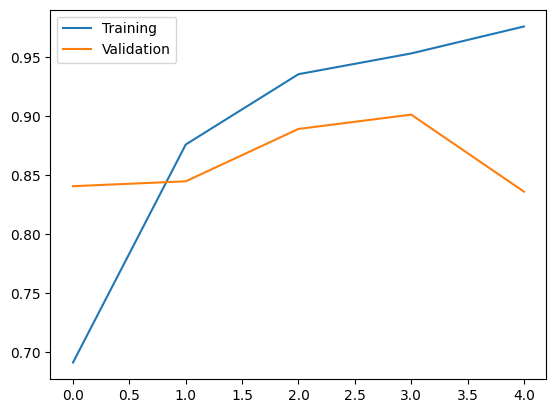

In [13]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.legend(["Training", "Validation"])
plt.show()

# Step 14: Add Early Stopping

In [14]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Step 15: Train the Improved Model

In [16]:
history = model.fit(
    train,
    validation_data=val,
    epochs=5,
    callbacks=[early_stop]
)

Epoch 1/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 420s 814ms/step - accuracy: 0.9827 - loss: 0.0540 - val_accuracy: 0.8866 - val_loss: 0.4618
Epoch 2/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 453s 835ms/step - accuracy: 0.9878 - loss: 0.0378 - val_accuracy: 0.8917 - val_loss: 0.4846
Epoch 3/5
516/516 ━━━━━━━━━━━━━━━━━━━━ 427s 827ms/step - accuracy: 0.9817 - loss: 0.0537 - val_accuracy: 0.8801 - val_loss: 0.5832


# Step 16:Evaluate the model's performance

In [17]:
loss, accuracy = model.evaluate(val)
print("Accuracy:", accuracy)

129/129 ━━━━━━━━━━━━━━━━━━━━ 27s 209ms/step - accuracy: 0.8866 - loss: 0.4618
Accuracy: 0.8866004347801208


# - Previous Accuracy: 83.62%
# - Improved Accuracy: 88.66%
## - Improvement: 5.04 percentage points
# - Previous Loss: 0.6177
# - Current Loss: 0.4618

# The model's validation accuracy improved from 83.62% to 88.66%, while the loss decreased from 0.6177 to 0.4618.

# Step 17: Accuracy Graph

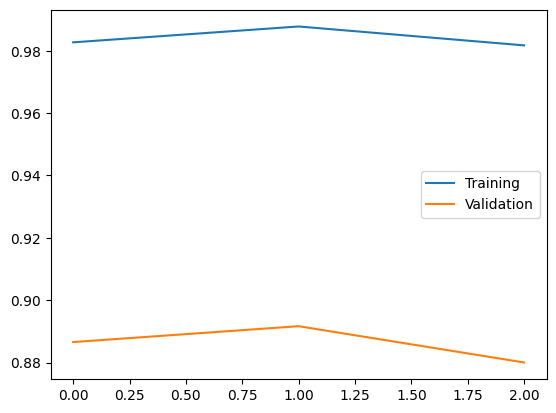

In [18]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.legend(["Training", "Validation"])
plt.show()

# Step 18: Image Prediction

In [22]:
img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

prediction = model.predict(img_array)
predicted_class = classes[prediction.argmax()]

print("Predicted Disease:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step
Predicted Disease: Pepper__bell___Bacterial_spot


# Step 19: Picture + Predicted Disease

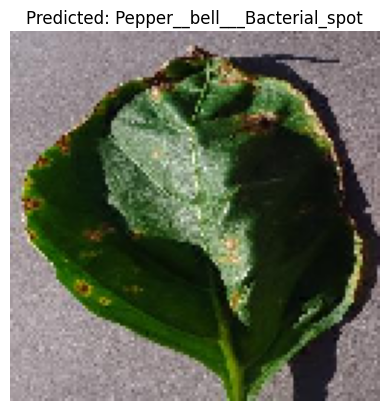

In [26]:
plt.imshow(img)
plt.title(f"Predicted: {predicted_class}")
plt.axis("off")
plt.show()

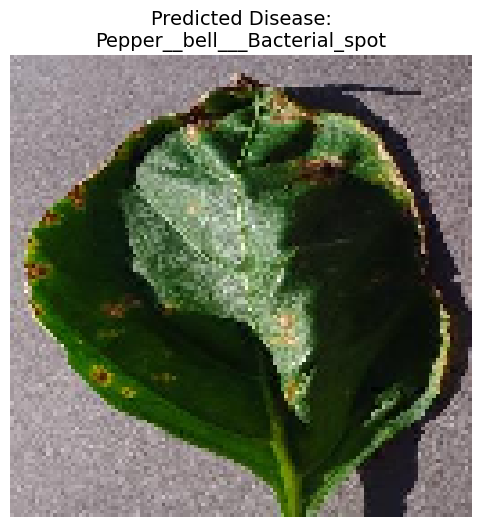

In [25]:
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title(
    f"Predicted Disease:\n{predicted_class}",
    fontsize=14
)
plt.axis("off")
plt.show()